# Overall confusion matrices on the test set (final model)

Final model: single split (no folds), CT + box mask input, class-weighted cross-entropy loss (`train_no_fold.py --mask --loss weighted`), runs in `runs/cls_no_fold_mask_weighted`.

One confusion matrix each for models A and B, combining seeds 1-3 on the 290 test nodules: every seed's
predictions are counted together, so each test nodule is counted once per seed (3 × 290 = 870 predictions).
Drawn with `_confusion_png` from `plots.py`, the same function as the per-run matrices:
cell numbers are counts, colour is the share of the row.

In [1]:
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
from IPython.display import Image, display

PROJECT = Path.cwd().parent if Path.cwd().name == "Model" else Path.cwd()
sys.path.insert(0, str(PROJECT / "Model"))       # plots.py
sys.path.insert(0, str(PROJECT / "pipeline"))    # metrics.py
from plots import _confusion_png

RUNS_DIR = PROJECT / "runs" / "cls_no_fold_mask_weighted"
OUT_DIR = PROJECT / "results" / "test_no_fold_mask_weighted"     # saved next to the other test results of this model
SEEDS = [1, 2, 3]
RATINGS = [1, 2, 3, 4, 5]
P_COLS = [f"p{k}" for k in RATINGS]
KINDS = {"hard": "A", "soft": "B"}

# check these are the final model's runs: CT + mask input, class-weighted loss
for kind in KINDS:
    for s in SEEDS:
        cfg = json.loads((RUNS_DIR / f"{kind}_seed{s}" / "config.json").read_text())
        assert cfg.get("mask") and cfg.get("loss") == "weighted", f"{kind}_seed{s} is not a mask + weighted run"

labels = pd.read_csv(PROJECT / "data" / "nodules_labels.csv")
test = labels[labels["split"] == "test"].set_index("nodule_key")
hard = test["hard"].to_numpy()
print(f"{len(test)} test nodules")

def probs_of(run):
    """One run's test probabilities, rows in the order of the test nodules."""
    preds = pd.read_csv(RUNS_DIR / run / "test_preds.csv").set_index("nodule_key")
    return preds.loc[test.index, P_COLS].to_numpy()

290 test nodules


## Combine each model's seeds, then draw and show the matrices

results/test_no_fold_mask_weighted/confusion_hard_pooled.png


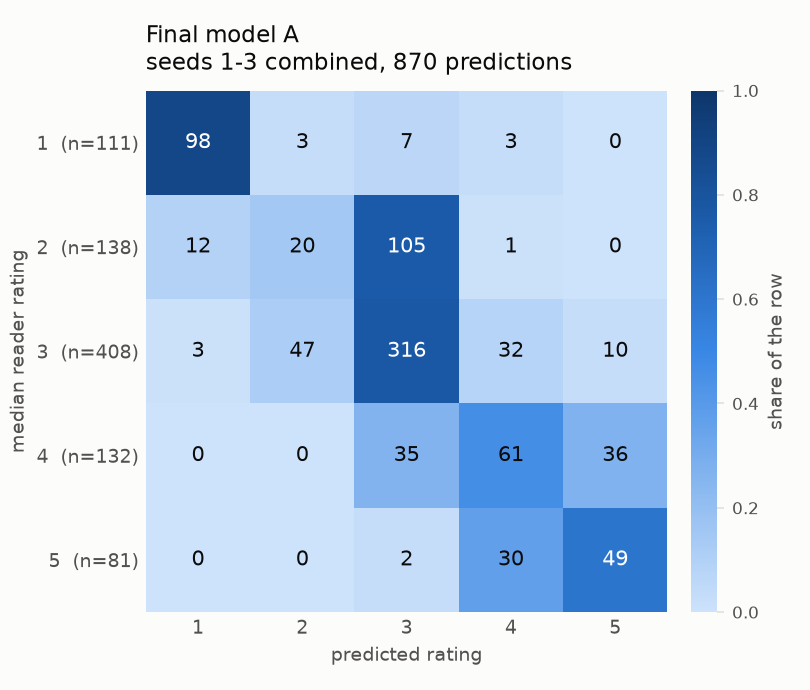

results/test_no_fold_mask_weighted/confusion_soft_pooled.png


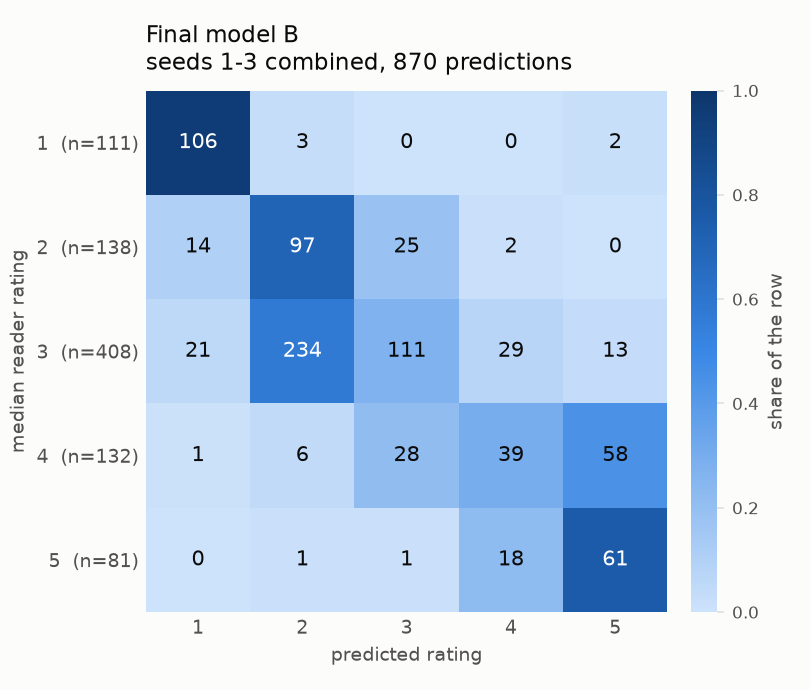

In [2]:
matplotlib.use("Agg")      # _confusion_png saves to a file; the saved file is shown below
for kind, m in KINDS.items():
    pred = np.concatenate([probs_of(f"{kind}_seed{s}").argmax(axis=1) + 1 for s in SEEDS])
    path = OUT_DIR / f"confusion_{kind}_pooled.png"
    _confusion_png(np.tile(hard, len(SEEDS)), pred,
                   f"Final model {m}\nseeds 1-3 combined, {len(pred)} predictions", path)
    print(path.relative_to(PROJECT))
    display(Image(filename=str(path), width=460))